In [1]:
import os, json, math, time, random
from pathlib import Path
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

DATA_DIR = "."          # shakespeare_train.txt / shakespeare_valid.txt 所在資料夾
OUT_DIR  = "outputs"    # 模型、history、圖片都存這裡 (三個 notebook 共用)
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available(): device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available(): device = torch.device("mps")
else: device = torch.device("cpu")
print("device:", device)

device: cuda


In [2]:
class CharTokenizer:
    def __init__(self, chars):
        self.chars = list(chars)
        self.stoi = {c: i for i, c in enumerate(self.chars)}
        self.itos = {i: c for c, i in self.stoi.items()}
    @classmethod
    def from_text(cls, text): return cls(sorted(set(text)))
    @property
    def vocab_size(self): return len(self.chars)
    def encode(self, text): return [self.stoi[c] for c in text if c in self.stoi]
    def decode(self, ids): return "".join(self.itos[int(i)] for i in ids)
    def to_dict(self): return {"type": "char", "chars": self.chars}

class BPETokenizer:
    def __init__(self, tk): self.tk = tk
    @classmethod
    def train(cls, text, vocab_size=1000):
        from tokenizers import Tokenizer, models, pre_tokenizers, decoders, trainers
        tk = Tokenizer(models.BPE())
        tk.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
        tk.decoder = decoders.ByteLevel()
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, show_progress=False,
                                      initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
        tk.train_from_iterator(text.splitlines(keepends=True), trainer)
        return cls(tk)
    @property
    def vocab_size(self): return self.tk.get_vocab_size()
    def encode(self, text): return self.tk.encode(text).ids
    def decode(self, ids): return self.tk.decode([int(i) for i in ids])
    def to_dict(self): return {"type": "bpe", "json": self.tk.to_str()}

def tokenizer_from_dict(d):
    if d["type"] == "char": return CharTokenizer(d["chars"])
    from tokenizers import Tokenizer
    return BPETokenizer(Tokenizer.from_str(d["json"]))

def build_tokenizer(kind, train_text, valid_text, bpe_vocab=1000):
    if kind == "char":   # 用 train+valid 建字表，避免 valid 出現沒見過的字元
        return CharTokenizer.from_text(train_text + valid_text)
    return BPETokenizer.train(train_text, bpe_vocab)

In [3]:
def sample_next(logits, temperature=1.0):
    # P(i) = exp(z_i / T) / sum_j exp(z_j / T)
    probs = F.softmax(logits / max(temperature, 1e-6), dim=-1)
    return torch.multinomial(probs, num_samples=1)

In [4]:
class LSTMLM(nn.Module):
    kind = "lstm"
    def __init__(self, vocab_size, emb_dim=256, hidden_dim=512, num_layers=2, dropout=0.3):
        super().__init__()
        self.config = dict(vocab_size=vocab_size, emb_dim=emb_dim, hidden_dim=hidden_dim,
                           num_layers=num_layers, dropout=dropout)
        self.emb = nn.Embedding(vocab_size, emb_dim)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, h=None, return_h=False):
        out, h = self.lstm(self.drop(self.emb(x)), h)
        logits = self.fc(self.drop(out))
        return (logits, h) if return_h else logits

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        self.eval()
        logits, h = self(idx, return_h=True)          # 先讀完 prompt
        for _ in range(max_new_tokens):
            nxt = sample_next(logits[:, -1], temperature)
            idx = torch.cat([idx, nxt], dim=1)
            logits, h = self(nxt, h, return_h=True)   # 之後只餵新 token，沿用 hidden state
        return idx

In [5]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head, self.dropout = n_head, dropout
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)
        self.attn_drop = nn.Dropout(dropout)
        self.res_drop = nn.Dropout(dropout)
        # causal mask：下三角為 True → 位置 t 只能看見 <= t
        mask = torch.tril(torch.ones(block_size, block_size, dtype=torch.bool))
        self.register_buffer("mask", mask.view(1, 1, block_size, block_size), persistent=False)
        self.store, self.last_attn = False, None      # store=True 時保存 attention (給 Q3 用)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        if self.store:                                 # 手動算，才拿得到 attention weights
            att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))
            att = att.masked_fill(~self.mask[:, :, :T, :T], float("-inf"))
            att = F.softmax(att, dim=-1)
            self.last_attn = att.detach()
            y = self.attn_drop(att) @ v
        else:                                          # 訓練用 fused kernel，is_causal=True 等價於上面的 mask
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True,
                                               dropout_p=self.dropout if self.training else 0.0)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.res_drop(self.proj(y))

class Block(nn.Module):
    def __init__(self, n_embd, n_head, ff_dim, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.mlp = nn.Sequential(nn.Linear(n_embd, ff_dim), nn.GELU(),
                                 nn.Linear(ff_dim, n_embd), nn.Dropout(dropout))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # pre-LN + residual
        return x + self.mlp(self.ln2(x))

class MiniGPT(nn.Module):
    kind = "transformer"
    def __init__(self, vocab_size, block_size=128, n_embd=256, n_head=4, n_layer=4, ff_dim=1024, dropout=0.2):
        super().__init__()
        self.config = dict(vocab_size=vocab_size, block_size=block_size, n_embd=n_embd,
                           n_head=n_head, n_layer=n_layer, ff_dim=ff_dim, dropout=dropout)
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)       # learned positional encoding
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block(n_embd, n_head, ff_dim, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)
            if isinstance(m, nn.Linear) and m.bias is not None: nn.init.zeros_(m.bias)

    def forward(self, idx):
        B, T = idx.shape
        x = self.drop(self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device)))
        for blk in self.blocks: x = blk(x)
        return self.head(self.ln_f(x))

    @torch.no_grad()
    def get_last_layer_attention(self, idx):
        self.eval()
        attn = self.blocks[-1].attn
        attn.store = True; self(idx); attn.store = False
        return attn.last_attn[0].cpu()                         # (n_head, T, T)

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        self.eval()
        for _ in range(max_new_tokens):
            ctx = idx[:, -self.block_size:]                    # 只看最後 block_size 個 token
            nxt = sample_next(self(ctx)[:, -1], temperature)
            idx = torch.cat([idx, nxt], dim=1)
        return idx

In [6]:
def load_ckpt(path):
    ck = torch.load(path, map_location=device)
    cls = LSTMLM if ck["kind"] == "lstm" else MiniGPT
    m = cls(**ck["config"]).to(device)
    m.load_state_dict(ck["state"]); m.eval()
    return m, tokenizer_from_dict(ck["tok"])

gpt, tok = load_ckpt(os.path.join(OUT_DIR, "transformer.pt"))
models = {"Transformer": gpt}
if os.path.exists(os.path.join(OUT_DIR, "lstm.pt")):
    models["LSTM"], _ = load_ckpt(os.path.join(OUT_DIR, "lstm.pt"))
print("loaded:", list(models), "| vocab:", tok.vocab_size)

def token_labels(ids):
    return [(tok.decode([i]).replace("\n", "\\n").replace(" ", "␣") or "?") for i in ids]

loaded: ['Transformer', 'LSTM'] | vocab: 67


In [7]:
ATTN_PROMPT = "ROMEO:\nBut soft, what"          # 21 個字元；BPE 時 token 會較少，可改長一點
ids = tok.encode(ATTN_PROMPT)
print(f"prompt token 數 = {len(ids)}（建議 15~25）")
att = gpt.get_last_layer_attention(torch.tensor([ids], device=device))   # (H, T, T)
labels = token_labels(ids)
print("attention shape:", tuple(att.shape))

prompt token 數 = 21（建議 15~25）
attention shape: (4, 21, 21)


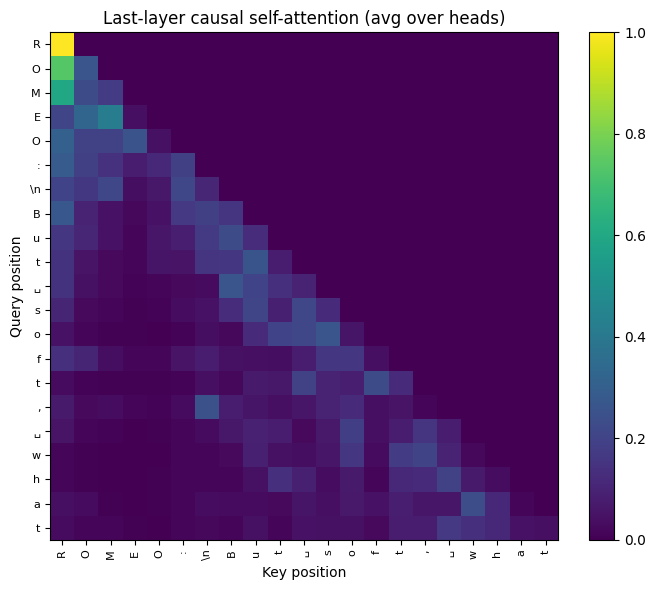

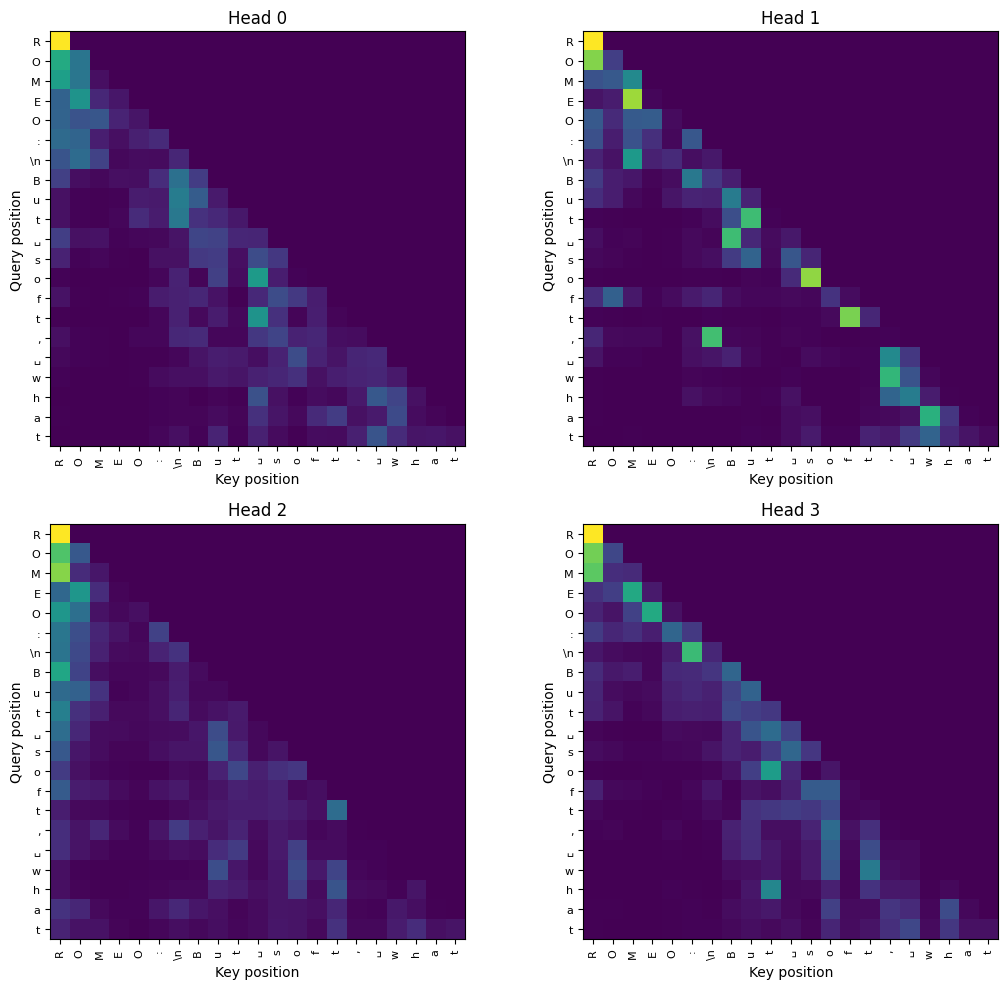

In [8]:
def heatmap(ax, mat, title):
    im = ax.imshow(mat, cmap="viridis", vmin=0, vmax=float(mat.max()))
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=90, fontsize=8)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("Key position"); ax.set_ylabel("Query position"); ax.set_title(title)
    return im

# (a) 各 head 平均 —— 對應題目的 Figure 1
fig, ax = plt.subplots(figsize=(7, 6))
im = heatmap(ax, att.mean(0).numpy(), "Last-layer causal self-attention (avg over heads)")
fig.colorbar(im, ax=ax, fraction=0.046); fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "attn_avg.png"), dpi=200); plt.show()

# (b) 每個 head
H = att.size(0); cols = 2 if H <= 4 else 4; rows = (H + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(5.5 * cols, 5 * rows), squeeze=False)
for h in range(rows * cols):
    ax = axes[h // cols][h % cols]
    if h < H: heatmap(ax, att[h].numpy(), f"Head {h}")
    else: ax.axis("off")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "attn_heads.png"), dpi=200); plt.show()

In [9]:
avg = att.mean(0)
print(f"上三角 (未來位置) 的注意力總和 = {torch.triu(avg, diagonal=1).sum():.2e}  ← 應為 0，即下三角結構")
print("每一列總和 (應為 1):", [round(float(v), 3) for v in avg.sum(1)[:5]], "...\n")

print("標點 / 換行 / 空白 token 的 top-3 注意位置 (head 平均)：")
for q, i in enumerate(ids):
    ch = tok.decode([i])
    if ch in "\n:,.;!?'" or ch.strip() == "":
        top = torch.topk(avg[q, : q + 1], k=min(3, q + 1))
        desc = ", ".join(f"{labels[j]}@{j}({w:.2f})" for w, j in zip(top.values.tolist(), top.indices.tolist()))
        print(f"  query {labels[q]!r:>6}@{q:<2} → {desc}")

上三角 (未來位置) 的注意力總和 = 0.00e+00  ← 應為 0，即下三角結構
每一列總和 (應為 1): [1.0, 1.0, 1.0, 1.0, 1.0] ...

標點 / 換行 / 空白 token 的 top-3 注意位置 (head 平均)：
  query    ':'@5  → R@0(0.29), O@1(0.19), :@5(0.19)
  query  '\\n'@6  → M@2(0.21), :@5(0.21), R@0(0.20)
  query    '␣'@10 → B@7(0.26), u@8(0.20), R@0(0.15)
  query    ','@15 → \n@6(0.25), o@12(0.12), s@11(0.10)
  query    '␣'@16 → o@12(0.18), ,@15(0.15), u@8(0.09)


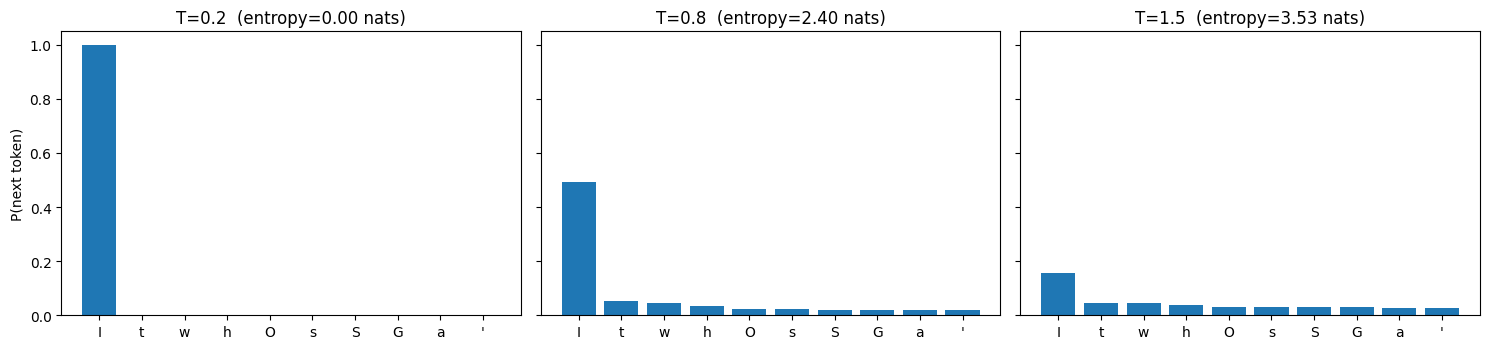

In [10]:
GEN_PROMPT = "ROMEO: "
TEMPS = [0.2, 0.8, 1.5]
MAX_NEW = 600           # char-level 約 10~15 行；BPE 可調小

# (a) 單一步驟的下一個 token 機率分佈如何隨 T 改變
x = torch.tensor([tok.encode(GEN_PROMPT)], device=device)
with torch.no_grad(): logits = gpt(x)[0, -1]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, T in zip(axes, TEMPS):
    p = F.softmax(logits / T, dim=-1).cpu()
    top = torch.topk(p, 10)
    entropy = -(p * torch.log(p + 1e-12)).sum().item()
    ax.bar(range(10), top.values.numpy()); ax.set_xticks(range(10))
    ax.set_xticklabels(token_labels(top.indices.tolist()))
    ax.set_title(f"T={T}  (entropy={entropy:.2f} nats)")
axes[0].set_ylabel("P(next token)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "temperature_distribution.png"), dpi=200); plt.show()

In [11]:
import re
train_text = Path(DATA_DIR, "shakespeare_train.txt").read_text(encoding="utf-8")
train_words = set(w.lower() for w in re.findall(r"[A-Za-z']+", train_text))

ids0 = torch.tensor([tok.encode(GEN_PROMPT)], device=device)
rows, dump = [], []
for name, m in models.items():
    for T in TEMPS:
        torch.manual_seed(0)                              # 固定 seed，不同溫度才可公平比較
        text = tok.decode(m.generate(ids0, MAX_NEW, T)[0].tolist())
        words = re.findall(r"[A-Za-z']+", text)
        valid = sum(w.lower() in train_words for w in words) / max(1, len(words))   # 拼字合法比例
        uniq = len(set(words)) / max(1, len(words))                                  # 多樣性
        rows.append((name, T, valid, uniq))
        head = f"==================== {name} | T={T} ===================="
        shown = "\n".join(text.split("\n")[:15])                                     # 只顯示前 15 行
        print(head + "\n" + shown + "\n")
        dump.append(head + "\n" + text + "\n")
Path(OUT_DIR, "temperature_samples.txt").write_text("\n".join(dump), encoding="utf-8")

print("| Model | T | valid-word rate | unique-word ratio |\n|---|---|---|---|")
for n, T, v, u in rows: print(f"| {n} | {T} | {v:.1%} | {u:.1%} |")

==================== Transformer | T=0.2 ====================
ROMEO: I will not stay to the court of the world.

BENEDICK:
I will not see thee to the court of thee.

BEATRICE:
I will not see thee to the court of thy head.

BEATRICE:
I will not see thee to the cause of the world.

BENEDICK:
I will not see thy lord.

BEATRICE:

==================== Transformer | T=0.8 ====================
ROMEO: Proteus, for his brother will be a grief.
The like landed will not stop their finger grosses,
Yet they are like a bloody service.

GARDINER:
So have I too seen, as air as the sun
That I am to again the time because we met,
But in my faithful assault:
Let not the caused flout in her house.
Romeo, he is the town of return her desire,
More dangerous turnets of many things are all thy name.
I never have the heavens bear from my words,
Who are well they would have every thing
At the melting desire of his honour.
I have the soldier of their death to the house,

==================== Transformer | T=1.5 